# Cluster-fold analysis

In [1]:
import os
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D

if 'google.colab' in str(get_ipython()):
    !git clone --config lfs.fetchinclude="*"  https://github.com/sinc-lab/xvalRNAfolding.git
    DATA_PATH = './xvalRNAfolding/'
    # similarity matrix and blastn table, not in the repository (see the README)
    !mkdir -p ./xvalRNAfolding/data/archiveII/distances
    !curl -sL -o ./xvalRNAfolding/data/archiveII/distances/seqsim_f_all.h5 "https://drive.usercontent.google.com/download?export=download&confirm=t&id=1qLPI9ePyUksuJ7eu3Q8PV-kIMhC5NXDC"
    !curl -sL -o ./xvalRNAfolding/data/archiveII/distances/archiveII-blastn-allvall-nofilter.tsv "https://drive.usercontent.google.com/download?export=download&confirm=t&id=1z3AOAutA0tsU16wnIrge6PhkByPk7IXj"
else:
    DATA_PATH = '../'

DATA = Path(DATA_PATH) / "data" / "archiveII"
SPLIT_DIR = DATA / "multithreshold_clustering"
CLSTR_DIR = SPLIT_DIR / "clstr"
DIST_DIR = DATA / "distances"
FIG = Path(DATA_PATH) / "figures" / "archiveII"
FIG.mkdir(parents=True, exist_ok=True)

font_size = 6
linew = 0.8
plt.rcParams.update({'font.size': font_size, 'axes.linewidth': 0.5,
                     'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
                     'xtick.minor.width': 0.4, 'ytick.minor.width': 0.4,
                     'xtick.major.size': 2.5, 'ytick.major.size': 2.5})

classical_methods = ["RNAfold", "RNAstructure", "LinearFoldV", "LinearPartitionV", "ProbKnot", "IPKnot"]

dataset = pd.read_csv(DATA / "archiveII.csv", index_col="id")

In [2]:
def get_tp(bp_x, bp_ref, strict):
    tp = 0
    for rbp in bp_x:
        cond = rbp in bp_ref
        if not strict:
            cond = cond or [rbp[0], rbp[1] - 1] in bp_ref or [rbp[0], rbp[1] + 1] in bp_ref or [rbp[0] + 1, rbp[1]] in bp_ref or [rbp[0] - 1, rbp[1]] in bp_ref
        if cond:
            tp += 1
    return tp

def bp_metrics(ref_bp, pre_bp, strict=True):
    """F1, recall and precision from base pairs."""
    if len(ref_bp) == 0 and len(pre_bp) == 0:
        return 1.0, 1.0, 1.0

    tp1 = get_tp(pre_bp, ref_bp, strict)
    tp2 = get_tp(ref_bp, pre_bp, strict)
    fn = len(ref_bp) - tp1
    fp = len(pre_bp) - tp1

    tpr = pre = f1 = 0.0
    if tp1 + fn > 0:
        tpr = tp1 / float(tp1 + fn)
    if tp1 + fp > 0:
        pre = tp2 / float(tp1 + fp)
    if tpr + pre > 0:
        f1 = 2 * pre * tpr / (pre + tpr)

    return f1, tpr, pre

In [3]:
sys.path.insert(0, DATA_PATH + "src")
from summaries import classical_summary as load_classical_summary, load_summary

classical_summary = load_classical_summary("archiveII")

pred_root = f"{DATA_PATH}predictions/archiveII/clustering_folds/sincFold_multithreshold"
summary_th = []
for name in sorted(os.listdir(pred_root)):
    tag, th = name[len("clustering_"):].rsplit("_", 1)
    variant = "rep" if tag.endswith("rep") else "full"
    tool = tag[:-3] if variant == "rep" else tag

    splits = pd.read_csv(SPLIT_DIR / f"{name}_folds_split.csv", index_col="id")

    for fold in sorted(splits["fold_number"].unique()):
        partition_set = splits[(splits["fold_number"] == fold) & (splits["partition"] == "test")]
        pred = pd.read_csv(f"{pred_root}/{name}/{fold}/pred.csv", index_col="id")
        pred["ref"] = dataset.loc[pred.index, "base_pairs"]
        pred[["f1", "rec", "pre"]] = pred.apply(lambda x: bp_metrics(json.loads(x["ref"]), json.loads(x["base_pairs"])), axis=1, result_type="expand")
        pred["method"] = "sincFold"

        for res in [pred] + [classical_summary.loc[partition_set.index].query("method == @m").copy() for m in classical_methods]:
            res[["tool", "th", "fold", "variant"]] = tool, int(th), fold, variant
            summary_th.append(res[["method", "tool", "th", "fold", "variant", "f1", "rec", "pre"]])

# original cluster-fold split = cd-hit at 80%
res = load_summary("archiveII", "clustering_folds")
res = res[res["method"].isin(["sincFold"] + classical_methods)].copy()
res[["tool", "th", "variant"]] = "cdhit", 80, "full"
summary_th = pd.concat(summary_th + [res[["method", "tool", "th", "fold", "variant", "f1", "rec", "pre"]]])

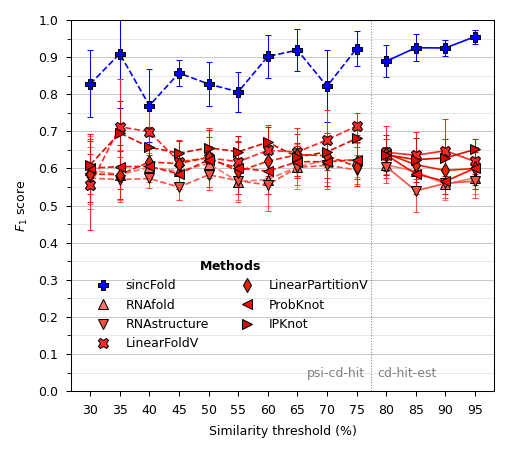

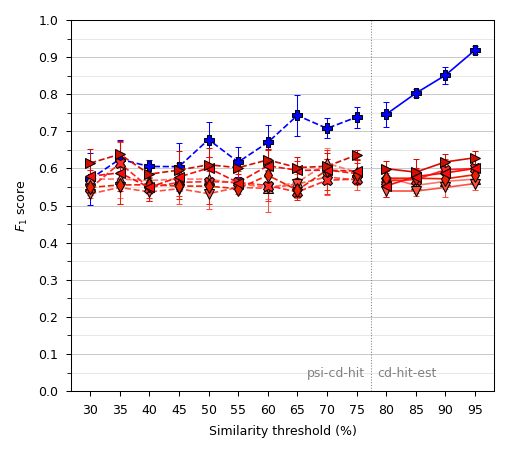

In [4]:
# style globals, as in Figure_2_strips_plot
marker_colors = ["#6A6AFA", "#6262F8", "#2929FB", "#0000FF",
                 "#FF746C", "#FC5141", "#FF2727", "#ED2100", "#FD0A0A", "#D20E00"]
mmarkers = ['o', 's', 'D', 'P', '^', 'v', 'X', 'd', '<', '>']
marker_sizes = 0.1 * np.array([35, 30, 30, 45, 50, 50, 50, 50, 50, 50]) # adjusted for smaller figures

# index of each method in the style lists (trained methods 0-3, classical 4-9)
method_idx = {"sincFold": 3}
for i, m in enumerate(classical_methods):
    method_idx[m] = 4 + i
tool_style = {"psi": "--", "cdhit": "-", "mmseqs": "-."}


def f1_vs_threshold(summary_th, variant, title=None, include_legend=False):
    fig_width1col = 6.75/2 # "2in2col"
    fig_height = 3.0

    fig, ax = plt.subplots(figsize=(fig_width1col, fig_height), dpi=150)
    plt.rcParams.update({'font.size': font_size})

    handles = []
    for method in ["sincFold"] + classical_methods:
        i = method_idx[method]
        for tool, ls in tool_style.items():
            sub = summary_th[(summary_th["method"] == method) & (summary_th["tool"] == tool)
                             & (summary_th["variant"] == variant)]
            if len(sub) == 0:
                continue
            # median over folds of the per-fold median F1
            stats = sub.groupby(["th", "fold"])["f1"].median().reset_index().groupby("th")["f1"].agg(["median", "std"])
            ax.errorbar(stats.index, stats["median"], yerr=stats["std"],
                        color=marker_colors[i], marker=mmarkers[i], linestyle=ls,
                        markersize=marker_sizes[i], linewidth=0.8, elinewidth=0.5, capsize=1.5,
                        markeredgecolor='black', markeredgewidth=0.5)
        handles.append(Line2D([0], [0], marker=mmarkers[i], color='w',
                              markerfacecolor=marker_colors[i], markeredgecolor='black',
                              markeredgewidth=0.5, markersize=marker_sizes[i], linestyle='',
                              label=method))

    ax.axvline(77.5, color="grey", linestyle=":", linewidth=0.5)
    ax.text(76.5, 0.03, "psi-cd-hit", ha="right", va="bottom", fontsize=font_size, color="grey")
    ax.text(78.5, 0.03, "cd-hit-est", ha="left", va="bottom", fontsize=font_size, color="grey")

    ax.set_xticks(sorted(summary_th[summary_th["variant"] == variant]["th"].unique()))
    plt.xticks(fontsize=font_size)
    plt.yticks(fontsize=font_size)
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(0.1))
    ax.yaxis.set_minor_locator(mticker.MultipleLocator(0.05))
    ax.grid(axis="y", which="major", color="grey", linewidth=0.4, alpha=0.5)
    ax.grid(axis="y", which="minor", color="grey", linewidth=0.3, alpha=0.3)
    ax.set_axisbelow(True)

    plt.xlabel("Similarity threshold (%)", fontsize=font_size)
    plt.ylabel("$F_1$ score", fontsize=font_size)
    if title is not None:
        plt.title(title, fontsize=font_size)
    if include_legend:
        ax.legend(handles=handles, title=r"$\mathbf{Methods}$", loc="lower left",
                  bbox_to_anchor=(0.02, 0.08), ncol=2, fontsize=font_size,
                  title_fontsize=font_size, frameon=False)
    plt.tight_layout()


for variant, title in [("full", "All cluster sequences"), ("rep", "Representatives only")]:
    f1_vs_threshold(summary_th, variant, None, include_legend=(variant == "full"))
    plt.savefig(FIG / f"Fig_F1_vs_clustering_threshold_{variant}.pdf", bbox_inches='tight', dpi=300)
    plt.show()

- **cluster-fold**: all sequences; psi-cd-hit below 80%, cd-hit-est from 80% up.
- **cluster-fold (representatives)**: one sequence per cluster of the same clusterings.
- **sim-fold**: the sim-fold splits, one sequence per group.

For each sequence, the **nearest-neighbour similarity** is its similarity to the most
similar sequence of *another cluster*. In the representatives and sim-fold splits every
sequence is its own cluster, so it is the most similar other sequence kept in the set.
A sequence above the dotted diagonal has an inter-cluster neighbour at or above the
threshold.

Similarity is measured two ways, both in % (100 = identical):

- **cd-hit/psi metric**: sequence identity from an all-vs-all `blastn`.
- **sim-fold metric**: the matrix `seqsim_f_all.h5` used by the sim-fold generator. 

In [5]:
SIM_THS = [40, 50, 60, 70, 80, 90]
SETS = [("cluster", "#2a78d6", "o", "cluster-fold"),
        ("cluster-rep", "#eb6834", "^", "cluster-fold (representatives)"),
        ("sim-fold", "#2f9e44", "D", "sim-fold")]

IDS = list(dataset.index)
N = len(IDS)
POS = {i: k for k, i in enumerate(IDS)}


def set_key(variant, th):
    if variant == "sim-fold":
        return ("sim", th, False)
    tool = "psi" if th < 80 else "cdhit"                 # psi below 80, cd-hit from 80 up
    return (tool, th, variant == "cluster-rep")


def split_path(tool, th, rep=False):
    if tool == "sim":
        return DATA / "sim_folds_split" / f"sim{th}.csv"
    return SPLIT_DIR / f"clustering_{tool}{'rep' if rep else ''}_{th}_folds_split.csv"


def load_clusters(tool, th):
    id2c, cur = {}, None
    for line in open(CLSTR_DIR / f"archiveII-{tool}_{th / 100:g}.clstr"):
        if line.startswith(">"):
            cur = int(line.split()[-1])
        else:
            id2c[line.split(">", 1)[1].split("...")[0]] = cur
    return id2c


SPLITS = {set_key(v, th): pd.read_csv(split_path(*set_key(v, th)))
          for v, *_ in SETS for th in SIM_THS}
CLUSTERS = {set_key("cluster", th)[:2]: load_clusters(*set_key("cluster", th)[:2])
            for th in SIM_THS}

In [6]:
def load_simfold_metric():
    v = np.array(pd.read_hdf(DIST_DIR / "seqsim_f_all.h5").loc[IDS, IDS].values, dtype=np.float32, copy=True) * 100
    np.fill_diagonal(v, 0)
    return v


def load_cdhit_metric():
    tsv = DIST_DIR / "archiveII-blastn-allvall-nofilter.tsv" # not in the repository, see the README for the download link
    b = pd.read_csv(tsv, sep="\t", header=None, names=["q", "s", "nident", "qlen", "slen"])
    b = b[(b.q != b.s) & b.q.isin(POS) & b.s.isin(POS)]
    ident = (b.nident * 100.0 / np.minimum(b.qlen, b.slen)).to_numpy(np.float32)
    qi, si = b.q.map(POS).to_numpy(), b.s.map(POS).to_numpy()
    v = np.zeros((N, N), np.float32)
    o = np.argsort(ident)
    v[qi[o], si[o]] = ident[o]
    v = np.maximum(v, v.T)
    np.fill_diagonal(v, 0)
    return v


METRICS = {"cd-hit/psi": load_cdhit_metric(), "sim-fold": load_simfold_metric()}
MLABEL = {"cd-hit/psi": "cd-hit/psi metric (blastn identity)", "sim-fold": "sim-fold metric"}

In [7]:
def nearest_neighbour(sp, M, id2c=None):
    """Per sequence: similarity to the most similar sequence of another cluster.
    Without id2c every sequence is its own cluster."""
    ids = sorted(set(sp.id))
    idx = np.array([POS[i] for i in ids])
    S = M[np.ix_(idx, idx)]
    if id2c is not None:
        lab = np.array([id2c[i] for i in ids])
        S = np.where(lab[:, None] == lab[None, :], -1, S)
    return S.max(axis=1)


NN = {}
for variant, *_ in SETS:
    for th in SIM_THS:
        key = set_key(variant, th)
        id2c = CLUSTERS[key[:2]] if variant == "cluster" else None
        for mname, M in METRICS.items():
            NN[(variant, th, mname)] = nearest_neighbour(SPLITS[key], M, id2c)

One box per threshold and split; whiskers span the 5th-95th percentile. Each point is
one sequence (jittered horizontally), so points beyond the whiskers are the 10% outside
that range. The share of each box above the diagonal is the share of sequences with a
neighbour in another cluster at or above the threshold.

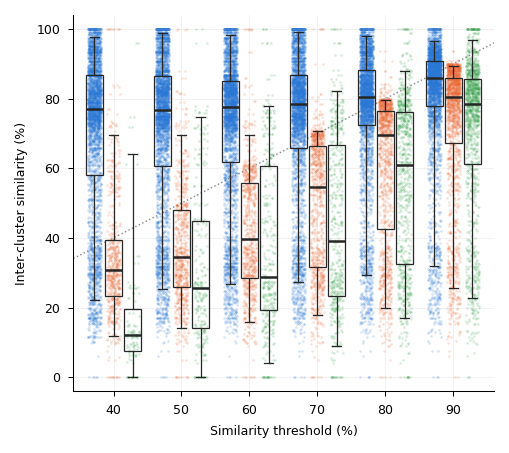

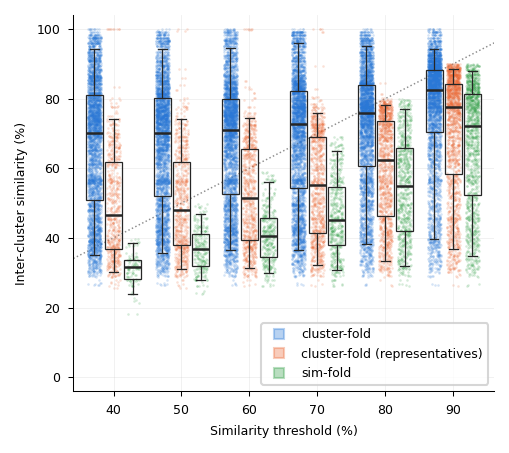

In [8]:
BOX_OFFSET = {"cluster": -2.8, "cluster-rep": 0.0, "sim-fold": 2.8}
BOX_W = 2.4
MSLUG = {"cd-hit/psi": "cdhit_psi", "sim-fold": "simfold"}


def nn_vs_threshold(mname, include_legend=False):
    fig_width1col = 6.75/2 # "2in2col"
    fig_height = 3.0

    fig, ax = plt.subplots(figsize=(fig_width1col, fig_height), dpi=150)
    plt.rcParams.update({'font.size': font_size})

    rng = np.random.default_rng(0)
    for variant, color, marker, label in SETS:
        for th in SIM_THS:
            y = NN[(variant, th, mname)]
            x = th + BOX_OFFSET[variant] + rng.uniform(-0.4, 0.4, len(y)) * BOX_W
            ax.scatter(x, y, s=1.5, color=color, alpha=0.2, lw=0, zorder=1, rasterized=True)
        ax.boxplot([NN[(variant, th, mname)] for th in SIM_THS],
                   positions=[th + BOX_OFFSET[variant] for th in SIM_THS], widths=BOX_W,
                   whis=(5, 95), showfliers=False, patch_artist=True, manage_ticks=False,
                   zorder=2,
                   boxprops=dict(facecolor="none", edgecolor="0.15", lw=0.6),
                   medianprops=dict(color="0.15", lw=1.2),
                   whiskerprops=dict(color="0.15", lw=0.6),
                   capprops=dict(color="0.15", lw=0.6))
    ax.plot([26, 104], [26, 104], color="0.55", lw=0.7, ls=":", zorder=0)

    ax.set_xlim(34, 96)
    ax.set_xticks(SIM_THS)
    ax.set_ylim(-4, 104)
    ax.grid(alpha=0.2, lw=0.4)
    ax.spines[["top", "right"]].set_visible(False)
    plt.xticks(fontsize=font_size)
    plt.yticks(fontsize=font_size)
    plt.xlabel("Similarity threshold (%)", fontsize=font_size)
    plt.ylabel("Inter-cluster similarity (%)", fontsize=font_size)
    #plt.title(MLABEL[mname], fontsize=font_size)
    if include_legend:
        h = [Line2D([], [], color=c, marker="s", ls="none", ms=5, mfc=c + "55") for _, c, _, _ in SETS]
        ax.legend(h, [lab for *_, lab in SETS], loc="lower right", fontsize=font_size)
    plt.tight_layout()


for mname in METRICS:
    nn_vs_threshold(mname, include_legend=(mname == "sim-fold"))
    plt.savefig(FIG / f"Fig_nearest_neighbour_vs_threshold_{MSLUG[mname]}.pdf", bbox_inches='tight', dpi=300)
    plt.show()